In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('DataCoSupplyChainDataset.csv', encoding='cp1252')

In [3]:
df.shape

(180519, 53)

In [6]:
df['Late_delivery_risk'].value_counts()

Late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64

In [7]:
risk_percentage = df['Late_delivery_risk'].mean() * 100

print("Overall Delay Risk:", round(risk_percentage, 2), "%")

Overall Delay Risk: 54.83 %


In [8]:
shipping_risk = df.groupby('Shipping Mode').agg(
    Total_Orders=('Order Id', 'count'),
    Delay_Risk=('Late_delivery_risk', 'mean')
).reset_index()

shipping_risk['Delay_Risk'] = shipping_risk['Delay_Risk'] * 100

shipping_risk

,Shipping Mode,Total_Orders,Delay_Risk
0,First Class,27814,95.322499
1,Same Day,9737,45.743042
2,Second Class,35216,76.632781
3,Standard Class,107752,38.071683


In [9]:
category_risk = df.groupby('Category Name').agg(
    Total_Orders=('Order Id', 'count'),
    Delay_Risk=('Late_delivery_risk', 'mean')
).reset_index()

category_risk['Delay_Risk'] = category_risk['Delay_Risk'] * 100

category_risk = category_risk.sort_values(
    by='Delay_Risk', ascending=False
)

category_risk.head(10)

,Category Name,Total_Orders,Delay_Risk
23,Golf Bags & Carts,61,68.852459
32,Lacrosse,343,60.058309
37,Pet Supplies,492,58.943089
8,Cameras,592,58.108108
41,Strength Training,111,57.657658
1,As Seen on TV!,68,57.352941
36,Music,434,57.142857
0,Accessories,1780,56.966292
19,Fitness Accessories,309,56.957929
5,Books,405,56.543210


In [10]:
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)']
)

df['Month'] = df['order date (DateOrders)'].dt.to_period('M')

monthly_risk = df.groupby('Month').agg(
    Total_Orders=('Order Id', 'count'),
    Delay_Risk=('Late_delivery_risk', 'mean')
).reset_index()

monthly_risk['Delay_Risk'] = monthly_risk['Delay_Risk'] * 100

monthly_risk['Month'] = monthly_risk['Month'].astype(str)

monthly_risk

,Month,Total_Orders,Delay_Risk
0,2015-01,5322,54.114994
1,2015-02,4729,54.853034
2,2015-03,5362,54.755688
3,2015-04,5126,53.843153
4,2015-05,5357,55.086802
5,2015-06,5134,54.109856
6,2015-07,5299,55.463295
7,2015-08,5273,55.679879
8,2015-09,5140,56.692607
9,2015-10,5302,54.809506


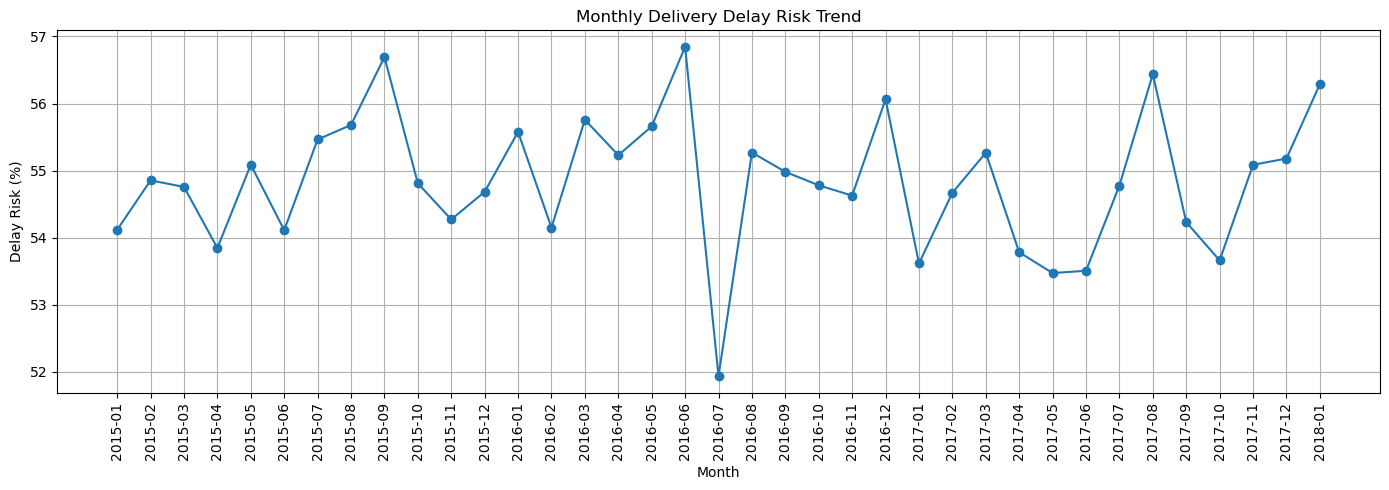

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,5))

plt.plot(
    monthly_risk['Month'],
    monthly_risk['Delay_Risk'],
    marker='o'
)

plt.title('Monthly Delivery Delay Risk Trend')
plt.xlabel('Month')
plt.ylabel('Delay Risk (%)')
plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()

In [12]:
risk_summary = pd.DataFrame({
    'Metric': [
        'Total Orders',
        'Overall Delay Risk (%)',
        'Highest Risk Shipping Mode',
        'Highest Risk Category'
    ],
    'Value': [
        df['Order Id'].nunique(),
        round(risk_percentage, 2),
        shipping_risk.sort_values(
            'Delay_Risk', ascending=False
        ).iloc[0]['Shipping Mode'],
        category_risk.iloc[0]['Category Name']
    ]
})

risk_summary

,Metric,Value
0,Total Orders,65752
1,Overall Delay Risk (%),54.83
2,Highest Risk Shipping Mode,First Class
3,Highest Risk Category,Golf Bags & Carts


In [13]:
with pd.ExcelWriter('12_Delay_Risk_Analysis.xlsx') as writer:

    risk_summary.to_excel(
        writer, sheet_name='Risk Summary', index=False
    )

    shipping_risk.to_excel(
        writer, sheet_name='Shipping Risk', index=False
    )

    category_risk.to_excel(
        writer, sheet_name='Category Risk', index=False
    )

    monthly_risk.to_excel(
        writer, sheet_name='Monthly Trend', index=False
    )

print("Excel Report Created Successfully!")

Excel Report Created Successfully!
